# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

**Nama:** Zaki Zainuk Muttaqin  
**NIM:** 2410114016139
**Kelas:** Reg B 

Notebook ini menggunakan implementasi NumPy untuk model dan metrik evaluasi. `RANDOM_STATE = 39` sesuai dua digit terakhir NIM yang diberikan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 39
np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)

def train_test_split(X, y, test_size=0.2, random_state=39):
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))

def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    return np.array([[np.sum((y_true==0)&(y_pred==0)), np.sum((y_true==0)&(y_pred==1))],
                     [np.sum((y_true==1)&(y_pred==0)), np.sum((y_true==1)&(y_pred==1))]])

class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X).reshape(-1, 1)
        y = np.asarray(y).reshape(-1, 1)
        Xb = np.c_[np.ones(len(X)), X]
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_, self.coef_ = float(theta[0,0]), float(theta[1,0])
        return self
    def predict(self, X):
        X = np.asarray(X).reshape(-1,1)
        return self.intercept_ + self.coef_ * X[:,0]

def regression_metrics(y, pred):
    y, pred = np.asarray(y).ravel(), np.asarray(pred).ravel()
    mse = np.mean((y-pred)**2)
    denom = np.sum((y-np.mean(y))**2)
    return {'MAE':np.mean(np.abs(y-pred)), 'MSE':mse, 'RMSE':np.sqrt(mse),
            'R2':1-np.sum((y-pred)**2)/denom if denom else np.nan}

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr, self.n_iterations = learning_rate, n_iterations
    def fit(self, X, y):
        X = np.asarray(X).reshape(-1,1)
        y = np.asarray(y).ravel()
        # Standardisasi fitur membantu membandingkan learning rate secara stabil.
        self.x_mean, self.x_std = X.mean(), X.std()
        if self.x_std == 0: self.x_std = 1
        Z = (X[:,0]-self.x_mean)/self.x_std
        self.y_mean, self.y_std = y.mean(), y.std()
        if self.y_std == 0: self.y_std = 1
        Y = (y-self.y_mean)/self.y_std
        Zb = np.c_[np.ones(len(Z)), Z]
        theta = np.zeros(2)
        self.loss_history = []
        for _ in range(self.n_iterations):
            err = Zb @ theta - Y
            self.loss_history.append(np.mean(err**2))
            theta -= self.lr * (2/len(Y)) * (Zb.T @ err)
        # Kembalikan parameter ke satuan asli X dan y.
        self.coef_ = theta[1] * self.y_std / self.x_std
        self.intercept_ = self.y_mean + theta[0]*self.y_std - self.coef_*self.x_mean
        return self
    def predict(self, X):
        return self.intercept_ + self.coef_*np.asarray(X).reshape(-1)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1/(1+np.exp(-z))

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.lr, self.n_iterations = learning_rate, n_iterations
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1
        Z = (X-self.mean_)/self.std_
        Zb = np.c_[np.ones(len(Z)), Z]
        theta = np.zeros(Zb.shape[1])
        self.loss_history = []
        for _ in range(self.n_iterations):
            p = sigmoid(Zb @ theta)
            eps = 1e-12
            self.loss_history.append(-np.mean(y*np.log(p+eps)+(1-y)*np.log(1-p+eps)))
            grad = Zb.T @ (p-y)/len(y)
            theta -= self.lr*grad
        self.intercept_ = theta[0] - np.sum(theta[1:]*self.mean_/self.std_)
        self.coef_ = theta[1:]/self.std_
        return self
    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return sigmoid(self.intercept_ + X @ self.coef_)
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp/(tp+fp) if tp+fp else 0
    recall = tp/(tp+fn) if tp+fn else 0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
    return {'Accuracy':accuracy_score(y_true,y_pred), 'TN':tn, 'FP':fp, 'FN':fn, 'TP':tp,
            'Precision':precision, 'Recall':recall, 'F1':f1}


# Menyimpan dataset agar notebook tetap bisa dijalankan jika CSV belum diunggah terpisah.
from pathlib import Path
ADS_CSV = r"""BiayaIklan,Penjualan
0.8,34.3
0.9,38.8
1.0,33.2
1.3,36.0
1.7,51.3
1.9,50.9
2.4,50.0
2.5,50.6
2.6,52.9
2.7,50.0
2.7,52.8
2.9,55.6
3.3,68.0
3.4,51.7
4.0,70.9
4.3,78.4
4.4,62.9
4.7,72.4
4.8,73.8
4.9,72.0
5.0,70.9
5.1,68.4
5.2,61.5
5.3,80.5
5.4,56.4
5.8,84.7
5.8,87.3
6.0,76.5
6.6,92.4
7.0,97.0
7.0,97.1
7.1,90.4
7.9,103.0
8.9,111.2
9.0,105.6
9.2,109.2
9.3,117.8
9.7,113.7
9.8,121.1
9.9,119.7"""
EMAIL_CSV = r"""JumlahLink,KataPromo,Spam
0,0,0
2,4,0
6,7,1
10,8,1
8,7,1
9,11,1
0,6,0
0,8,0
6,5,0
1,9,1
7,3,1
9,3,1
1,8,0
4,2,0
3,6,0
5,9,1
4,4,0
3,12,1
4,5,0
2,1,0
9,8,1
1,7,1
6,0,0
9,9,1
0,3,0
8,4,1
4,11,1
4,3,0
4,2,0
3,10,0
1,3,0
1,9,0
8,2,0
6,6,0
3,11,1
6,9,1
6,9,1
9,1,0
10,7,1
8,1,0
6,6,1
4,6,0
4,9,1
7,4,0
3,10,1
2,4,0
9,5,1
9,12,1
2,5,0
4,7,0
9,1,0
6,0,0
0,5,0
1,4,0
7,10,1
0,11,0
3,9,0
8,10,1
7,1,0
4,7,0"""
Path('Ads_Data.csv').write_text(ADS_CSV, encoding='utf-8')
Path('Email_Data.csv').write_text(EMAIL_CSV, encoding='utf-8')


397

## Bagian A – Linear Regression

### A1 – Load & Visualisasi Data

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


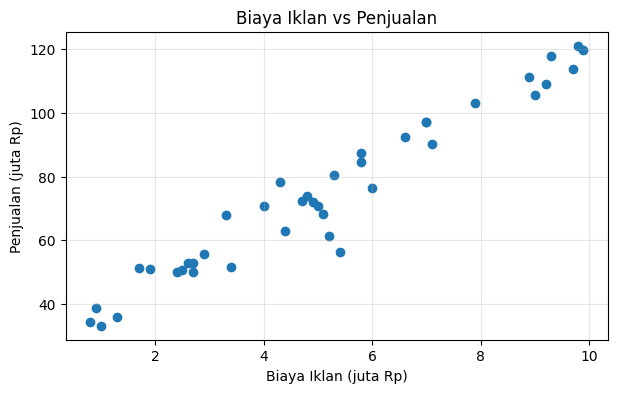

In [2]:
ads = pd.read_csv('Ads_Data.csv')
display(ads.head())
print('Jumlah baris:', len(ads))
X = ads[['BiayaIklan']].to_numpy()
y = ads['Penjualan'].to_numpy()
print('Shape X:', X.shape, '| Shape y:', y.shape)
plt.figure(figsize=(7,4))
plt.scatter(X[:,0], y)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, alpha=.3)
plt.show()

### A2 – Split Data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### A3 – Training Normal Equation

In [4]:
lin = LinearRegression().fit(X_train, y_train)
print('Intercept (b):', lin.intercept_)
print('Koefisien (m):', lin.coef_)
print(f'Persamaan regresi: ŷ = {lin.intercept_:.4f} + ({lin.coef_:.4f} × BiayaIklan)')

Intercept (b): 29.429596916977136
Koefisien (m): 8.945593123729516
Persamaan regresi: ŷ = 29.4296 + (8.9456 × BiayaIklan)


**Jawaban A3 (interpretasi):**  
Koefisien menunjukkan perkiraan perubahan penjualan untuk setiap kenaikan biaya iklan sebesar Rp1 juta. Jika koefisien positif, penjualan diperkirakan meningkat sebesar nilai koefisien tersebut (juta Rp), dengan asumsi hubungan linear.

### A4 – Evaluasi Model

In [5]:
metrics_A4 = pd.DataFrame([
    {'Data':'Training', **regression_metrics(y_train, lin.predict(X_train))},
    {'Data':'Testing', **regression_metrics(y_test, lin.predict(X_test))}
]).set_index('Data')
display(metrics_A4)

,MAE,MSE,RMSE,R2
Data,,,,
Training,4.6829,40.5038,6.3643,0.9387
Testing,4.0044,19.8542,4.4558,0.9395


**Jawaban A4 (analisis):**  
RMSE menunjukkan rata-rata besar kesalahan prediksi dalam satuan penjualan (juta Rp); semakin kecil semakin baik. R² menunjukkan seberapa baik model menjelaskan variasi penjualan; nilai mendekati 1 umumnya lebih baik. Gunakan tabel di atas untuk menilai hasil training dan testing. Jika hasil testing jauh lebih buruk daripada training, kemampuan generalisasi model perlu diperhatikan.

### A5 – Gradient Descent & Learning Rate

Learning rate=0.001: intercept=29.4318, koefisien=8.9452, loss akhir (skala standar)=0.061350


Learning rate=0.02: intercept=29.4296, koefisien=8.9456, loss akhir (skala standar)=0.061350
Learning rate=0.1: intercept=29.4296, koefisien=8.9456, loss akhir (skala standar)=0.061350


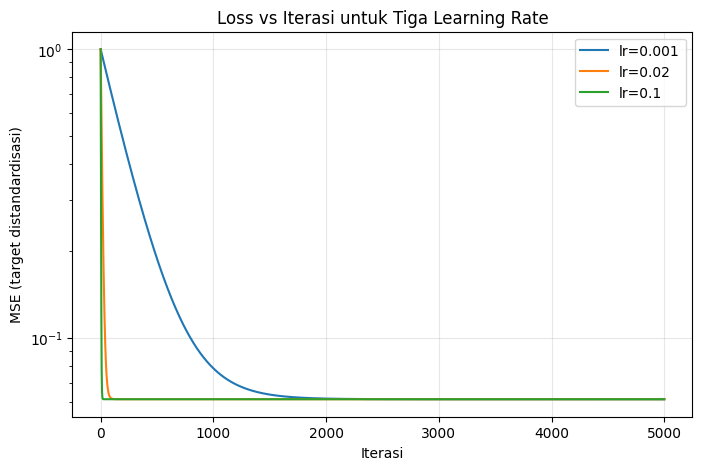

Normal equation: 29.429596916977136 8.945593123729516


In [6]:
gd_models = {}
for lr in [0.001, 0.02, 0.1]:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model
    print(f'Learning rate={lr}: intercept={model.intercept_:.4f}, koefisien={model.coef_:.4f}, '
          f'loss akhir (skala standar)={model.loss_history[-1]:.6f}')
plt.figure(figsize=(8,5))
for lr, model in gd_models.items():
    losses = np.asarray(model.loss_history)
    plt.plot(np.arange(1,len(losses)+1), np.maximum(losses,1e-12), label=f'lr={lr}')
plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('MSE (target distandardisasi)')
plt.title('Loss vs Iterasi untuk Tiga Learning Rate')
plt.legend()
plt.grid(True, alpha=.3)
plt.show()
print('Normal equation:', lin.intercept_, lin.coef_)

**Jawaban A5 (analisis):**  
Bandingkan koefisien hasil gradient descent dengan normal equation. Learning rate 0.001 biasanya belajar lebih lambat; learning rate yang lebih besar dapat mencapai nilai stabil lebih cepat, tetapi jika terlalu besar loss dapat berosilasi atau divergen. Grafik loss di atas menjadi dasar untuk menentukan mana yang lambat, stabil, atau gagal konvergen. Standardisasi fitur dan target diterapkan di implementasi ini agar eksperimen learning rate lebih terkendali.

### A6 – Visualisasi & Prediksi

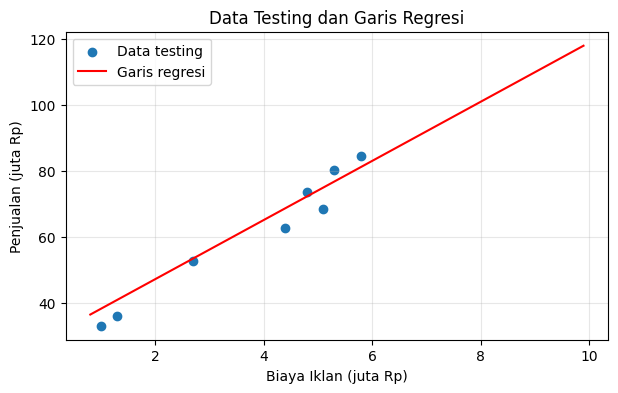

,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,69.6848
1,7.0,92.0487
2,12.0,136.7767


In [7]:
plt.figure(figsize=(7,4))
plt.scatter(X_test[:,0], y_test, label='Data testing')
x_line = np.linspace(X[:,0].min(), X[:,0].max(), 100)
plt.plot(x_line, lin.predict(x_line), color='red', label='Garis regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.title('Data Testing dan Garis Regresi')
plt.legend()
plt.grid(True, alpha=.3)
plt.show()
nilai_iklan = np.array([4.5, 7.0, 12.0]).reshape(-1,1)
prediksi = lin.predict(nilai_iklan)
display(pd.DataFrame({'BiayaIklan (juta Rp)':nilai_iklan[:,0], 'Prediksi Penjualan (juta Rp)':prediksi}))

**Jawaban A6 (analisis):**  
Prediksi untuk biaya iklan 4,5 dan 7 juta lebih dapat dipertimbangkan jika masih berada dalam rentang data yang diamati. Prediksi 12 juta merupakan ekstrapolasi karena melampaui rentang data (maksimum sekitar 9,9 juta), sehingga lebih tidak dapat dipercaya; hubungan linear belum tentu berlanjut di luar data.

## Bagian B – Logistic Regression

### B1 – Load & Visualisasi Data

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah tiap kelas (0=Bukan Spam, 1=Spam):


,Jumlah
Spam,
Bukan Spam,35
Spam,25


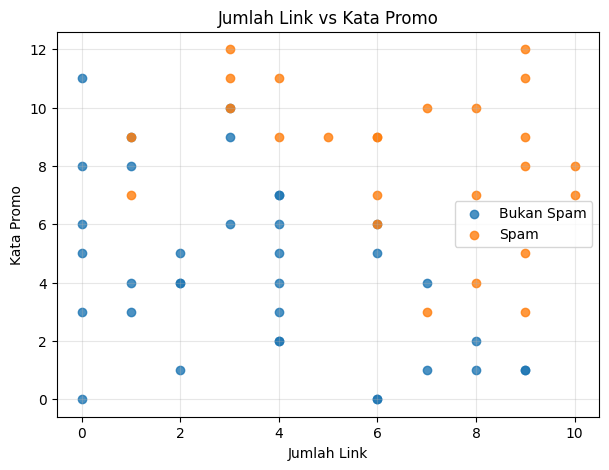

In [8]:
email = pd.read_csv('Email_Data.csv')
display(email.head())
print('Jumlah tiap kelas (0=Bukan Spam, 1=Spam):')
display(email['Spam'].value_counts().sort_index().rename(index={0:'Bukan Spam',1:'Spam'}).to_frame('Jumlah'))
Xc = email[['JumlahLink','KataPromo']].to_numpy(dtype=float)
yc = email['Spam'].to_numpy(dtype=int)
plt.figure(figsize=(7,5))
for label, name in [(0,'Bukan Spam'),(1,'Spam')]:
    mask = yc == label
    plt.scatter(Xc[mask,0], Xc[mask,1], label=name, alpha=.8)
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Jumlah Link vs Kata Promo')
plt.legend()
plt.grid(True, alpha=.3)
plt.show()

### B2 – Split Data & Training

X_train: (45, 2) | X_test: (15, 2)


Intercept (b):

 -8.730935697828881
Koefisien (m1, m2): [0.8172 0.7414]
P(Spam) = sigmoid(-8.7309 + (0.8172 × JumlahLink) + (0.7414 × KataPromo))


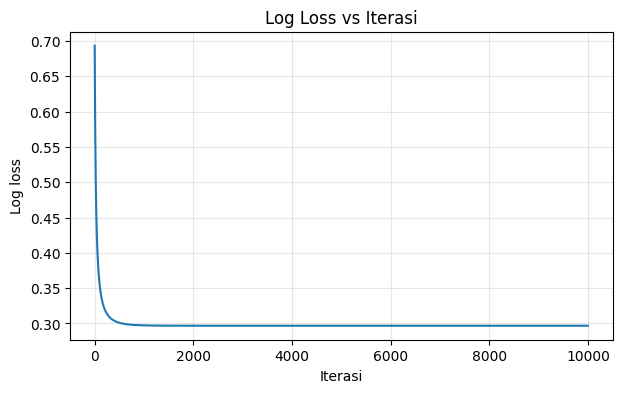

Loss awal: 0.6931471805579454 | Loss akhir: 0.29681424300353626


In [9]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=RANDOM_STATE)
print('X_train:', Xc_train.shape, '| X_test:', Xc_test.shape)
logit = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xc_train, yc_train)
print('Intercept (b):', logit.intercept_)
print('Koefisien (m1, m2):', logit.coef_)
print(f'P(Spam) = sigmoid({logit.intercept_:.4f} + ({logit.coef_[0]:.4f} × JumlahLink) + ({logit.coef_[1]:.4f} × KataPromo))')
plt.figure(figsize=(7,4))
plt.plot(logit.loss_history)
plt.xlabel('Iterasi')
plt.ylabel('Log loss')
plt.title('Log Loss vs Iterasi')
plt.grid(True, alpha=.3)
plt.show()
print('Loss awal:', logit.loss_history[0], '| Loss akhir:', logit.loss_history[-1])

**Jawaban B2 (analisis):**  
Perhatikan grafik log loss. Jika loss menurun lalu relatif stabil, model telah belajar dan mendekati konvergensi. Koefisien positif berarti kenaikan fitur tersebut meningkatkan peluang spam menurut model, dengan fitur lain tetap.

### B3 – Evaluasi Model

In [10]:
prob_test = logit.predict_proba(Xc_test)
pred_test = (prob_test >= 0.5).astype(int)
print('Confusion matrix (baris=aktual 0,1; kolom=prediksi 0,1):')
print(confusion_matrix(yc_test, pred_test))
display(pd.DataFrame([classification_metrics(yc_test, pred_test)]))

Confusion matrix (baris=aktual 0,1; kolom=prediksi 0,1):
[[9 1]
 [0 5]]


,Accuracy,TN,FP,FN,TP,Precision,Recall,F1
0,0.9333,9,1,0,5,0.8333,1.0,0.9091


**Jawaban B3 (analisis):**  
FP adalah email bukan spam yang salah ditandai sebagai spam, sehingga email penting bisa masuk folder spam. FN adalah email spam yang salah dianggap bukan spam, sehingga spam masuk kotak masuk. Kesalahan yang lebih merugikan bergantung pada kebutuhan pengguna; untuk menghindari hilangnya email penting, FP sering dianggap sangat merugikan.

### B4 – Decision Boundary

Decision boundary: KataPromo = -(-8.7309 + (0.8172 × JumlahLink)) / (0.7414)


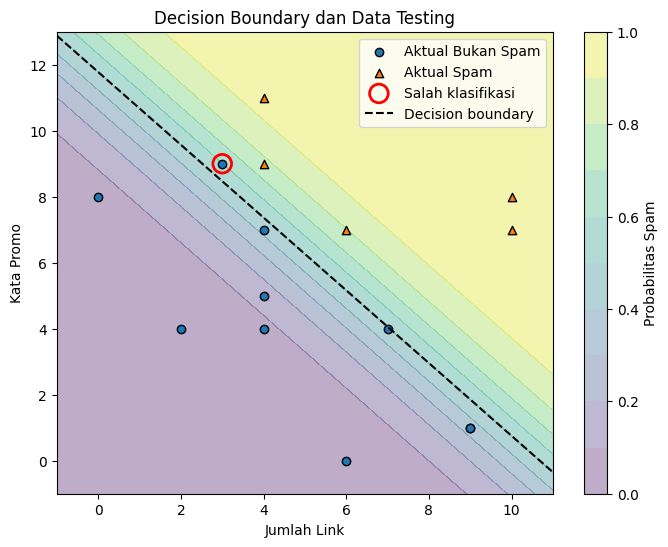

Indeks data testing yang salah klasifikasi (mulai dari 0): [7]


In [11]:
b = logit.intercept_
m1, m2 = logit.coef_
if abs(m2) > 1e-12:
    print(f'Decision boundary: KataPromo = -({b:.4f} + ({m1:.4f} × JumlahLink)) / ({m2:.4f})')
xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 200),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = logit.predict_proba(grid).reshape(xx.shape)
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, zz, levels=np.linspace(0,1,11), alpha=.35)
plt.colorbar(label='Probabilitas Spam')
for label, name, marker in [(0,'Bukan Spam','o'),(1,'Spam','^')]:
    mask = yc_test == label
    plt.scatter(Xc_test[mask,0], Xc_test[mask,1], label=f'Aktual {name}', marker=marker, edgecolors='black')
wrong = pred_test != yc_test
if wrong.any():
    plt.scatter(Xc_test[wrong,0], Xc_test[wrong,1], s=180, facecolors='none', edgecolors='red', linewidths=2, label='Salah klasifikasi')
if abs(m2) > 1e-12:
    xvals = np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 200)
    yvals = -(b + m1*xvals)/m2
    plt.plot(xvals, yvals, 'k--', label='Decision boundary')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.title('Decision Boundary dan Data Testing')
plt.legend()
plt.show()
print('Indeks data testing yang salah klasifikasi (mulai dari 0):', np.where(wrong)[0].tolist())

**Jawaban B4 (analisis):**  
Garis decision boundary menunjukkan kombinasi JumlahLink dan KataPromo saat probabilitas spam sama dengan 0,5. Titik yang dilingkari merah adalah data testing yang diprediksi berbeda dari label sebenarnya.

### B5 – Eksperimen Threshold

In [12]:
rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob_test >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    met = classification_metrics(yc_test, pred)
    rows.append({'Threshold':threshold, 'TN':met['TN'], 'FP':met['FP'], 'FN':met['FN'], 'TP':met['TP'],
                 'Precision':met['Precision'], 'Recall':met['Recall'], 'Accuracy':met['Accuracy']})
display(pd.DataFrame(rows).set_index('Threshold'))

,TN,FP,FN,TP,Precision,Recall,Accuracy
Threshold,,,,,,,
0.3,5,5,0,5,0.5000,1.0,0.6667
0.5,9,1,0,5,0.8333,1.0,0.9333
0.7,10,0,0,5,1.0000,1.0,1.0000


**Jawaban B5 (analisis):**  
Threshold lebih rendah membuat lebih banyak email diprediksi spam; recall biasanya meningkat, tetapi FP juga bisa bertambah dan precision dapat menurun. Threshold lebih tinggi membuat model lebih selektif menandai spam; precision bisa meningkat, tetapi lebih banyak spam mungkin lolos. Pilih threshold berdasarkan keseimbangan antara email spam yang lolos dan email penting yang salah masuk folder spam.

### B6 – Prediksi Email Baru

In [13]:
email_baru = pd.DataFrame({'Email':['E1','E2','E3','E4'],
                          'JumlahLink':[1,5,9,2],
                          'KataPromo':[2,6,10,11]})
# Pilihan threshold: 0.5 sebagai nilai standar; ubah jika memilih threshold lain dari B5.
THRESHOLD_PILIHAN = 0.5
X_baru = email_baru[['JumlahLink','KataPromo']].to_numpy(dtype=float)
email_baru['Probabilitas Spam'] = logit.predict_proba(X_baru)
email_baru['Prediksi'] = np.where(email_baru['Probabilitas Spam'] >= THRESHOLD_PILIHAN, 'Spam', 'Bukan Spam')
email_baru['Threshold'] = THRESHOLD_PILIHAN
display(email_baru)

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi,Threshold
0,E1,1,2,0.0016,Bukan Spam,0.5
1,E2,5,6,0.4509,Bukan Spam,0.5
2,E3,9,10,0.9976,Spam,0.5
3,E4,2,11,0.7424,Spam,0.5


## Bagian C – Pemahaman Konsep

**Jawaban C1:** Logistic Regression termasuk klasifikasi karena memprediksi kelas, misalnya spam atau bukan spam. Fungsi sigmoid mengubah skor model menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas.

**Jawaban C2:** Normal equation menghitung parameter secara langsung melalui operasi matriks, sedangkan gradient descent memperbarui parameter sedikit demi sedikit untuk menurunkan loss. Gradient descent lebih cocok untuk data besar atau banyak fitur karena tidak perlu menghitung invers matriks besar.

**Jawaban C3:** Data testing digunakan untuk mengukur kemampuan model pada data yang tidak dipakai saat pelatihan. Jika hanya dinilai pada data training, hasilnya bisa terlalu optimistis. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training dan kurang baik pada data baru.

**Jawaban C4:** Linear Regression memprediksi nilai kontinu, sehingga MSE mengukur rata-rata kuadrat selisih prediksi dan nilai sebenarnya. Logistic Regression memprediksi probabilitas kelas, sehingga log loss menilai seberapa baik probabilitas tersebut sesuai label sebenarnya dan memberi penalti besar pada prediksi yang sangat yakin tetapi salah.

**Jawaban C5:** Hasil dapat berbeda karena pembagian data training dan testing berbeda, misalnya akibat nilai random_state yang berbeda. Hasil juga dipengaruhi preprocessing, inisialisasi parameter, learning rate, jumlah iterasi, dan implementasi algoritma.

## Bonus – Perbandingan dengan scikit-learn

In [14]:
try:
    from sklearn.linear_model import LinearRegression as SkLinearRegression
    from sklearn.linear_model import LogisticRegression as SkLogisticRegression
    sk_lin = SkLinearRegression().fit(X_train, y_train)
    sk_lin_pred = sk_lin.predict(X_test)
    print('Linear Regression NumPy:', 'intercept=', lin.intercept_, 'coef=', lin.coef_,
          'R2 test=', regression_metrics(y_test, lin.predict(X_test))['R2'])
    print('Linear Regression sklearn:', 'intercept=', sk_lin.intercept_, 'coef=', sk_lin.coef_[0],
          'R2 test=', regression_metrics(y_test, sk_lin_pred)['R2'])
    sk_log = SkLogisticRegression(max_iter=10000, random_state=RANDOM_STATE).fit(Xc_train, yc_train)
    sk_pred = sk_log.predict(Xc_test)
    print('Logistic Regression NumPy:', 'intercept=', logit.intercept_, 'coef=', logit.coef_,
          'metrics=', classification_metrics(yc_test, pred_test))
    print('Logistic Regression sklearn:', 'intercept=', sk_log.intercept_[0], 'coef=', sk_log.coef_[0],
          'metrics=', classification_metrics(yc_test, sk_pred))
except ImportError:
    print('scikit-learn belum terpasang. Bonus opsional ini memerlukan instalasi scikit-learn.')


Linear Regression NumPy: intercept= 29.429596916977136 coef= 8.945593123729516 R2 test= 0.9395362978793012
Linear Regression sklearn: intercept= 29.429596916977324 coef= 8.945593123729482 R2 test= 0.9395362978792997
Logistic Regression NumPy: intercept= -8.730935697828881 coef= [0.8172 0.7414] metrics= {'Accuracy': np.float64(0.9333333333333333), 'TN': np.int64(9), 'FP': np.int64(1), 'FN': np.int64(0), 'TP': np.int64(5), 'Precision': np.float64(0.8333333333333334), 'Recall': np.float64(1.0), 'F1': np.float64(0.9090909090909091)}
Logistic Regression sklearn: intercept= -7.922670033443526 coef= [0.7384 0.6735] metrics= {'Accuracy': np.float64(0.9333333333333333), 'TN': np.int64(9), 'FP': np.int64(1), 'FN': np.int64(0), 'TP': np.int64(5), 'Precision': np.float64(0.8333333333333334), 'Recall': np.float64(1.0), 'F1': np.float64(0.9090909090909091)}


**Jawaban Bonus (analisis):**  
Hasil Linear Regression NumPy dan scikit-learn seharusnya sangat dekat karena keduanya menggunakan pendekatan kuadrat terkecil. Hasil Logistic Regression dapat berbeda karena scikit-learn menggunakan regularisasi secara default (L2) dan optimisasi yang berbeda. Parameter `C` mengatur kekuatan regularisasi; nilai `C` lebih besar berarti regularisasi lebih lemah.